# CSL236 - Introduction to AI & ML
## Data Preprocessing and Model Training

**Team Members:**
1. Vidhi Jindal - 24csu324
2. Palak Khanna - 24csu325

**Team Number:** ____________________

In [1]:
#A. Understanding the Data
#A1. Import libraries and load dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, RobustScaler
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load dataset
df = pd.read_csv("Road.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (12316, 32)


,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,...,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
0,17:02:00,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,Above 10yr,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Moving Backward,Slight Injury
1,17:02:00,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,5-10yrs,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury
2,17:02:00,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,NaN,...,Going straight,Driver or rider,Male,31-50,3,Driver,NaN,Not a Pedestrian,Changing lane to the left,Serious Injury
3,1:06:00,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Public (> 45 seats),Governmental,NaN,...,Going straight,Pedestrian,Female,18-30,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Slight Injury
4,1:06:00,Sunday,18-30,Male,Junior high school,Employee,2-5yr,NaN,Owner,5-10yrs,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury


In [2]:
#A2. Data type of every column
print("Data type of every column:\n")
print(df.dtypes)

Data type of every column:

Time                           object
Day_of_week                    object
Age_band_of_driver             object
Sex_of_driver                  object
Educational_level              object
Vehicle_driver_relation        object
Driving_experience             object
Type_of_vehicle                object
Owner_of_vehicle               object
Service_year_of_vehicle        object
Defect_of_vehicle              object
Area_accident_occured          object
Lanes_or_Medians               object
Road_allignment                object
Types_of_Junction              object
Road_surface_type              object
Road_surface_conditions        object
Light_conditions               object
Weather_conditions             object
Type_of_collision              object
Number_of_vehicles_involved     int64
Number_of_casualties            int64
Vehicle_movement               object
Casualty_class                 object
Sex_of_casualty                object
Age_band_of_casualty  

In [3]:
#A3. Summary statistics
#Numerical columns

print("Numerical Summary Statistics:")
display(df.describe())

Numerical Summary Statistics:


,Number_of_vehicles_involved,Number_of_casualties
count,12316.000000,12316.000000
mean,2.040679,1.548149
std,0.688790,1.007179
min,1.000000,1.000000
25%,2.000000,1.000000
50%,2.000000,1.000000
75%,2.000000,2.000000
max,7.000000,8.000000


In [4]:
#Categorical columns
print("Categorical Summary Statistics:")
display(df.describe(include='object').T)

Categorical Summary Statistics:


,count,unique,top,freq
Time,12316,1074,15:30:00,120
Day_of_week,12316,7,Friday,2041
Age_band_of_driver,12316,5,18-30,4271
Sex_of_driver,12316,3,Male,11437
Educational_level,11575,7,Junior high school,7619
Vehicle_driver_relation,11737,4,Employee,9627
Driving_experience,11487,7,5-10yr,3363
Type_of_vehicle,11366,17,Automobile,3205
Owner_of_vehicle,11834,4,Owner,10459
Service_year_of_vehicle,8388,6,Unknown,2883


In [5]:
#A4. Count and percentage of missing values
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

display(missing)

,Missing Count,Missing Percentage
Time,0,0.00
Day_of_week,0,0.00
Age_band_of_driver,0,0.00
Sex_of_driver,0,0.00
Educational_level,741,6.02
Vehicle_driver_relation,579,4.70
Driving_experience,829,6.73
Type_of_vehicle,950,7.71
Owner_of_vehicle,482,3.91
Service_year_of_vehicle,3928,31.89


In [6]:
#A5. Separate numerical and categorical columns
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()

categorical_columns = df.select_dtypes(include='object').columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nNumber of Numerical Columns:", len(numerical_columns))

print("\nCategorical Columns:")
print(categorical_columns)

print("\nNumber of Categorical Columns:", len(categorical_columns))

Numerical Columns:
['Number_of_vehicles_involved', 'Number_of_casualties']

Number of Numerical Columns: 2

Categorical Columns:
['Time', 'Day_of_week', 'Age_band_of_driver', 'Sex_of_driver', 'Educational_level', 'Vehicle_driver_relation', 'Driving_experience', 'Type_of_vehicle', 'Owner_of_vehicle', 'Service_year_of_vehicle', 'Defect_of_vehicle', 'Area_accident_occured', 'Lanes_or_Medians', 'Road_allignment', 'Types_of_Junction', 'Road_surface_type', 'Road_surface_conditions', 'Light_conditions', 'Weather_conditions', 'Type_of_collision', 'Vehicle_movement', 'Casualty_class', 'Sex_of_casualty', 'Age_band_of_casualty', 'Casualty_severity', 'Work_of_casuality', 'Fitness_of_casuality', 'Pedestrian_movement', 'Cause_of_accident', 'Accident_severity']

Number of Categorical Columns: 30


## B. Handling Missing Values

Missing values were identified using both their count and percentage. No rows or columns are dropped solely because of missing values because some categorical columns have a relatively high amount of missing data. Dropping those records would cause unnecessary loss of useful accident observations.

### Imputation strategy

- **Numerical features:** median imputation. The median is less affected by extreme values than the mean.
- **Ordinal categorical features:** most-frequent (mode) imputation.
- **Nominal categorical features:** most-frequent (mode) imputation.
- **Rows/columns:** not dropped because of missing values.

The imputers are fitted later **only on the training data** through the preprocessing pipelines, after the train/test split, to prevent data leakage.

In [7]:
#B. Handling Missing Values
missing_columns = df.columns[df.isnull().any()].tolist()

print("Columns containing missing values:")
print(missing_columns)

Columns containing missing values:
['Educational_level', 'Vehicle_driver_relation', 'Driving_experience', 'Type_of_vehicle', 'Owner_of_vehicle', 'Service_year_of_vehicle', 'Defect_of_vehicle', 'Area_accident_occured', 'Lanes_or_Medians', 'Road_allignment', 'Types_of_Junction', 'Road_surface_type', 'Type_of_collision', 'Vehicle_movement', 'Work_of_casuality', 'Fitness_of_casuality']


In [8]:
#B1. Missing-value table
missing_table = pd.DataFrame({
    "Column": df.columns,
    "Missing Count": df.isnull().sum().values,
    "Missing Percentage": (
        df.isnull().sum().values / len(df) * 100
    ).round(2)
})

missing_table = missing_table[
    missing_table["Missing Count"] > 0
]

display(missing_table)

,Column,Missing Count,Missing Percentage
4,Educational_level,741,6.02
5,Vehicle_driver_relation,579,4.70
6,Driving_experience,829,6.73
7,Type_of_vehicle,950,7.71
8,Owner_of_vehicle,482,3.91
9,Service_year_of_vehicle,3928,31.89
10,Defect_of_vehicle,4427,35.95
11,Area_accident_occured,239,1.94
12,Lanes_or_Medians,385,3.13
13,Road_allignment,142,1.15


## C. Encoding Categorical Data

Categorical variables are divided into ordinal and nominal variables. Ordinal variables have a meaningful order and are encoded with an explicitly defined order. Nominal variables have no natural order and are converted using one-hot encoding.

A binary 0/1 mapping is used only when a predictor genuinely has two categories; no predictor is artificially forced into a binary encoding. The target `Accident_severity` is kept separate from the input features.

In [10]:
#C. Encoding Categorical Data
#C1. Convert Time into hour
# Convert Time into hour
df['Hour'] = pd.to_datetime(
    df['Time'],
    format='%H:%M:%S'
).dt.hour

display(df[['Time', 'Hour']].head())


,Time,Hour
0,17:02:00,17
1,17:02:00,17
2,17:02:00,17
3,1:06:00,1
4,1:06:00,1


In [11]:
#C2. Binning Time

#We will create four meaningful time groups:

#0–5 → Night
#6–11 → Morning
#12–17 → Afternoon
#18–23 → Evening


def time_period(hour):
    if 0 <= hour <= 5:
        return "Night"
    elif 6 <= hour <= 11:
        return "Morning"
    elif 12 <= hour <= 17:
        return "Afternoon"
    else:
        return "Evening"

df['Time_period'] = df['Hour'].apply(time_period)

display(df[['Time', 'Hour', 'Time_period']].head(10))

,Time,Hour,Time_period
0,17:02:00,17,Afternoon
1,17:02:00,17,Afternoon
2,17:02:00,17,Afternoon
3,1:06:00,1,Night
4,1:06:00,1,Night
5,14:15:00,14,Afternoon
6,17:30:00,17,Afternoon
7,17:20:00,17,Afternoon
8,17:20:00,17,Afternoon
9,17:20:00,17,Afternoon


In [12]:
#C3. Remove original Time and Hour
df.drop(['Time', 'Hour'], axis=1, inplace=True)

print(df.shape)

(12316, 32)


In [13]:
#separate target and input features.
X = df.drop('Accident_severity', axis=1)

y = df['Accident_severity']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (12316, 31)
y shape: (12316,)


### Important data-leakage rule

The train/test split is performed **before fitting any imputer, encoder, scaler, variance filter, or feature selector**. This ensures that information from the test set cannot influence the transformations learned from the training data.

After this split, every fitted preprocessing step uses `X_train` only and the learned transformation is then applied to `X_test`.

In [14]:
#C4. TRAIN/TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data shape: (9852, 31)
Testing data shape: (2464, 31)

Training target distribution:
Accident_severity
Slight Injury     8331
Serious Injury    1394
Fatal injury       127
Name: count, dtype: int64

Testing target distribution:
Accident_severity
Slight Injury     2084
Serious Injury     349
Fatal injury        31
Name: count, dtype: int64


In [15]:
#C5. Define Numerical Features
numeric_features = [
    'Number_of_vehicles_involved',
    'Number_of_casualties'
]

print("Numerical features:")
print(numeric_features)

Numerical features:
['Number_of_vehicles_involved', 'Number_of_casualties']


In [16]:
#C6. Define Ordinal Features
ordinal_features = [
    'Age_band_of_driver',
    'Educational_level',
    'Driving_experience',
    'Service_year_of_vehicle',
    'Age_band_of_casualty'
]

print("Ordinal features:")
print(ordinal_features)

Ordinal features:
['Age_band_of_driver', 'Educational_level', 'Driving_experience', 'Service_year_of_vehicle', 'Age_band_of_casualty']


In [17]:
#C7. Define ordinal order
ordinal_categories = [
    
    # Age_band_of_driver
    [
        'Under 18',
        '18-30',
        '31-50',
        'Over 51',
        'Unknown'
    ],
    
    # Educational_level
    [
        'Illiterate',
        'Writing & reading',
        'Elementary school',
        'Junior high school',
        'High school',
        'Above high school',
        'Unknown'
    ],
    
    # Driving_experience
    [
        'No Licence',
        'Below 1yr',
        '1-2yr',
        '2-5yr',
        '5-10yr',
        'Above 10yr',
        'unknown'
    ],
    
    # Service_year_of_vehicle
    [
        'Below 1yr',
        '1-2yr',
        '2-5yrs',
        '5-10yrs',
        'Above 10yr',
        'Unknown'
    ],
    
    # Age_band_of_casualty
    [
        'Under 18',
        '18-30',
        '31-50',
        'Over 51',
        '5',
        'na'
    ]
]

In [ ]:
#C8. Define nominal features
nominal_features = [
    col for col in X.columns
    if col not in numeric_features + ordinal_features
]

print("Nominal features:")
print(nominal_features)

print("\nNumber of nominal features:", len(nominal_features))

### C9. Preprocessing Strategy

The preprocessing pipelines apply the appropriate transformation to each feature group:

- Numerical features → median imputation + RobustScaler
- Ordinal categorical features → mode imputation + explicitly ordered ordinal encoding
- Nominal categorical features → mode imputation + one-hot encoding

The pipelines are fitted only after the train/test split.

In [19]:
#C9. Create preprocessing pipelines
#Median imputation + Robust Scaling.
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

In [20]:
#Ordinal pipeline
#Mode imputation + ordinal encoding.
ordinal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(
        categories=ordinal_categories,
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ))
])


In [21]:
#Nominal pipeline
#Mode imputation + One-Hot Encoding.
nominal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

In [22]:
#C10. Combine all preprocessing
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('ordinal', ordinal_pipeline, ordinal_features),
    ('nominal', nominal_pipeline, nominal_features)
])

In [23]:
#FIT preprocessing ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training data after encoding/scaling:",
      X_train_processed.shape)

print("Testing data after encoding/scaling:",
      X_test_processed.shape)

Training data after encoding/scaling: (9852, 183)
Testing data after encoding/scaling: (2464, 183)


## D. Binning / Discretization

The original `Time` variable contains exact times. To make it easier to interpret accident patterns, it is converted into four **domain-defined time bins**:

- **00:00–05:59 → Night**
- **06:00–11:59 → Morning**
- **12:00–17:59 → Afternoon**
- **18:00–23:59 → Evening**

These boundaries represent meaningful periods of the day and reduce the high-cardinality exact-time values to four interpretable categories.

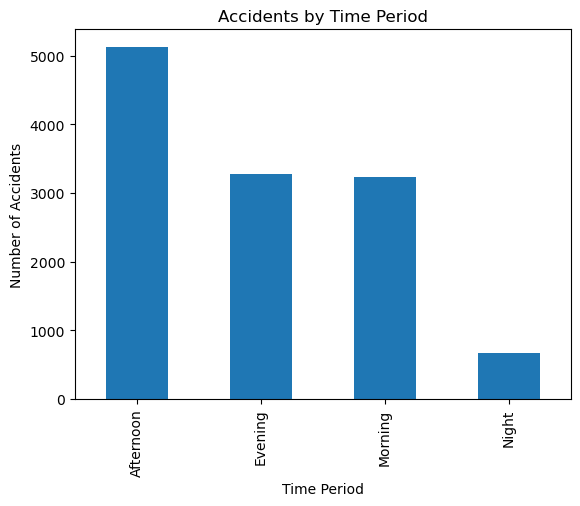

In [24]:
#D. Binning / Discretization
df['Time_period'].value_counts().plot(kind='bar')

plt.title("Accidents by Time Period")
plt.xlabel("Time Period")
plt.ylabel("Number of Accidents")
plt.show()

## E. Scaling / Transformation

The numerical variables are scaled using **RobustScaler**. RobustScaler uses the median and interquartile range, so it is less sensitive to extreme values than standard scaling.

The skewness of the numerical variables is examined below. A log transformation is not applied because the selected numerical variables are count-based accident features and the main preprocessing requirement is to reduce the influence of extreme observations.

The scaler is fitted only on the training data inside the preprocessing pipeline and then applied to the test data.

In [25]:
#E. Scaling / Transformation
print("Skewness of numerical features:")
print(df[numeric_features].skew())

Skewness of numerical features:
Number_of_vehicles_involved    1.323454
Number_of_casualties           2.344769
dtype: float64


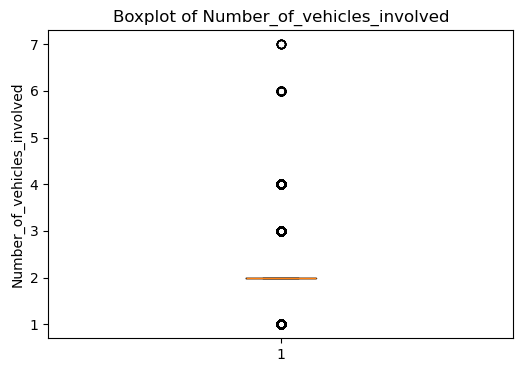

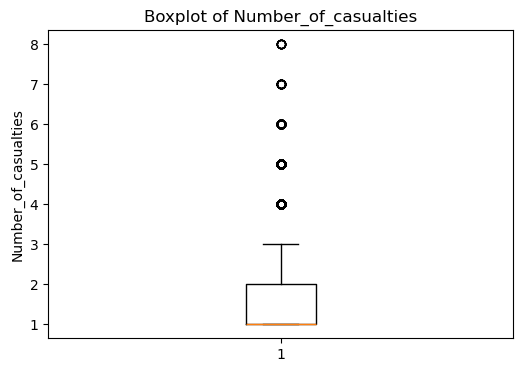

In [29]:
for col in numeric_features:
    plt.figure(figsize=(6, 4))
    plt.boxplot(df[col].dropna())
    plt.title("Boxplot of " + col)
    plt.ylabel(col)
    plt.show()

## F. Outlier Treatment

Outliers are investigated using the **IQR rule** and boxplots. An observation being outside the IQR limits does not automatically mean it is an error. In an accident dataset, unusually high numbers of vehicles or casualties can represent genuine events.

Therefore, the detected extreme observations are retained unless there is evidence of a data-entry error. RobustScaler is used to reduce their influence on the model.

In [30]:
#F. Outlier Treatment
#F1. Detect outliers using IQR
for col in numeric_features:
    
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]
    
    print("\nColumn:", col)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of outliers:", len(outliers))


Column: Number_of_vehicles_involved
Q1: 2.0
Q3: 2.0
IQR: 0.0
Lower Bound: 2.0
Upper Bound: 2.0
Number of outliers: 3976

Column: Number_of_casualties
Q1: 1.0
Q3: 2.0
IQR: 1.0
Lower Bound: -0.5
Upper Bound: 3.5
Number of outliers: 720


In [31]:
# F2. Treatment of Outliers

print("Outliers were investigated using the IQR method and boxplots.")
print("The detected extreme values are plausible accident observations rather than obvious data-entry errors.")
print("Therefore, they are retained instead of being deleted.")
print("RobustScaler is used during preprocessing to reduce the influence of extreme values.")


Outliers detected using the IQR method are genuine accident observations.
Therefore, they are retained and not deleted.
RobustScaler is used during preprocessing to reduce the influence of extreme values.


## G. Dimensionality Reduction / Feature Selection

One-hot encoding increases the number of input features because one categorical variable can become several binary columns. To reduce unnecessary dimensions, two feature-selection steps are used:

1. **VarianceThreshold** removes features with zero variance.
2. **SelectKBest with ANOVA F-test (`f_classif`)** selects the 50 most useful features with respect to the target.

The F-test is used instead of chi-square because RobustScaler can produce negative values, whereas chi-square requires non-negative inputs.

Feature-selection methods are fitted only on the training data and then applied to the test data. The notebook reports the feature count before and after each reduction step.

In [32]:
#G. Dimensionality Reduction / Feature Selection
#After One-Hot Encoding, the number of features becomes much larger.
print("Number of features before preprocessing:",
      X_train.shape[1])

print("Number of features after encoding:",
      X_train_processed.shape[1])

Number of features before preprocessing: 31
Number of features after encoding: 183


In [33]:
#G1. Remove zero-variance features
variance_filter = VarianceThreshold(threshold=0)

X_train_variance = variance_filter.fit_transform(
    X_train_processed
)

X_test_variance = variance_filter.transform(
    X_test_processed
)

print("Features after variance filtering:",
      X_train_variance.shape[1])

Features after variance filtering: 183


In [37]:
#G2. Select important features
from sklearn.feature_selection import SelectKBest, f_classif

# Select top 50 features
k = min(50, X_train_variance.shape[1])

selector = SelectKBest(
    score_func=f_classif,
    k=k
)

# Fit ONLY on training data
X_train_selected = selector.fit_transform(
    X_train_variance,
    y_train
)

# Transform test data
X_test_selected = selector.transform(
    X_test_variance
)

print("Features retained after feature selection:",
      X_train_selected.shape[1])

Features retained after feature selection: 50


In [38]:
print("----- DIMENSIONALITY REDUCTION -----")

print("Original features:", X_train.shape[1])
print("After encoding:", X_train_processed.shape[1])
print("After variance filtering:", X_train_variance.shape[1])
print("Final selected features:", X_train_selected.shape[1])

----- DIMENSIONALITY REDUCTION -----
Original features: 31
After encoding: 183
After variance filtering: 183
Final selected features: 50


## H. Model Training and Evaluation

Logistic Regression is used as the classification model for predicting `Accident_severity`.

The target classes are imbalanced: `Slight Injury` has many more observations than `Serious Injury` and `Fatal injury`. Therefore, `class_weight='balanced'` is used so that minority classes receive greater weight during training.

The model is trained only on the selected training features and evaluated on the unseen test data using accuracy, precision, recall, F1-score, and a confusion matrix.

In [44]:
#H. Model Training
#H1. Train Logistic Regression
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=3000,
    class_weight='balanced',
    random_state=42
)

model.fit(
    X_train_selected,
    y_train
)

print("Model training completed.")

Model training completed.


In [45]:
#H2. Make predictions
y_pred = model.predict(X_test_selected)

print("Predictions completed.")

Predictions completed.


In [47]:
#H3. Check predicted classes
print("Actual classes in test data:")
print(y_test.value_counts())

print("\nPredicted classes:")
print(pd.Series(y_pred).value_counts())

Actual classes in test data:
Accident_severity
Slight Injury     2084
Serious Injury     349
Fatal injury        31
Name: count, dtype: int64

Predicted classes:
Slight Injury     1205
Serious Injury     787
Fatal injury       472
Name: count, dtype: int64


In [48]:
#H4. Evaluate the model
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

Accuracy: 0.48944805194805197

Classification Report:
                precision    recall  f1-score   support

  Fatal injury       0.02      0.32      0.04        31
Serious Injury       0.17      0.39      0.24       349
 Slight Injury       0.88      0.51      0.65      2084

      accuracy                           0.49      2464
     macro avg       0.36      0.41      0.31      2464
  weighted avg       0.77      0.49      0.58      2464



In [49]:
#H5. Confusion Matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[  10   10   11]
 [  81  135  133]
 [ 381  642 1061]]


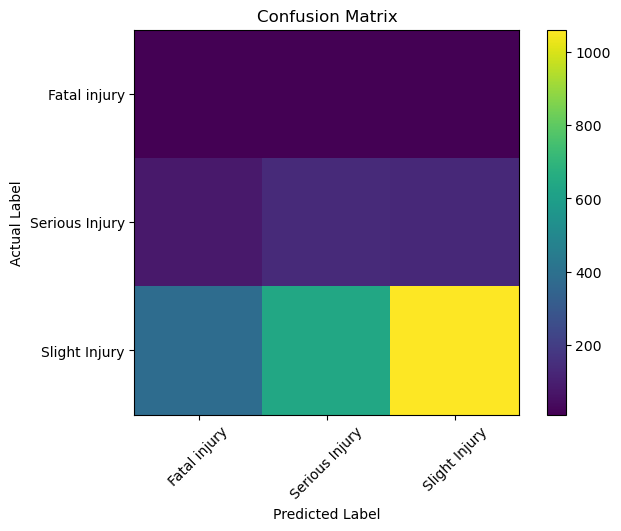

In [50]:
plt.figure(figsize=(7, 5))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks(
    range(len(model.classes_)),
    model.classes_,
    rotation=45
)

plt.yticks(
    range(len(model.classes_)),
    model.classes_
)

plt.colorbar()

plt.show()

### Class-distribution check

The class distribution is reported for both the training and test sets to make the class imbalance transparent and to support the use of `class_weight='balanced'`.

In [51]:
print("Training class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training class distribution:
Accident_severity
Slight Injury     8331
Serious Injury    1394
Fatal injury       127
Name: count, dtype: int64

Testing class distribution:
Accident_severity
Slight Injury     2084
Serious Injury     349
Fatal injury        31
Name: count, dtype: int64
